<a href="https://colab.research.google.com/github/leonIceHot/Computer-Vision-Course/blob/main/CH3_%E5%B9%BE%E4%BD%95%E8%BD%89%E6%8F%9B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔄 OpenCV Geometric Transformations

## 學習目標
- 掌握影像的縮放（Scaling）操作
- 理解影像的旋轉（Rotation）技術
- 學習仿射變換（Affine Transformation）
- 實作透視變換（Perspective Transformation）
- 應用影像翻轉與平移

---

## 📚 幾何變換基礎概念 (Geometric Transformation)

- 什麼是幾何變換？

  - **幾何變換**是改變影像的幾何結構，包括位置、方向、大小和形狀的操作。

- 主要類型
  - 🔍 **縮放（Scaling）**: 改變影像大小
  - 🔄 **旋轉（Rotation）**: 旋轉影像角度
  - ↔️ **翻轉（Flipping）**: 水平或垂直翻轉
  - 📐 **仿射變換（Affine）**: 保持平行線的變換
  - 🎭 **透視變換（Perspective）**: 模擬3D視角變化

## 🔍 1.影像縮放（Scaling）

- 縮放方法
  - 1. 縮小影像（Downscaling）— cv2.INTER_AREA
    - 面積平均取樣，縮小時品質最好、不易出現摩爾紋。注意它只在縮小時是面積平均，放大時會退化為接近最近鄰。
  - 2. 放大影像（追求速度）— cv2.INTER_LINEAR
    - 雙線性插值，OpenCV 的預設值，速度與品質平衡。
  - 3. 放大影像（追求高畫質）— cv2.INTER_CUBIC
    - 雙三次插值，品質較高、速度較慢。
  - 4. 縮放學習遮罩（Mask）／像素畫 — cv2.INTER_NEAREST
    - 最近鄰插值，速度最快、品質最低。遮罩與分類標籤存的是類別編號，其餘插值會算出 3.7、8.2 這類不存在的類別值，只有最近鄰能保證不產生新標籤。

Please enter scale: 2
Original Image:


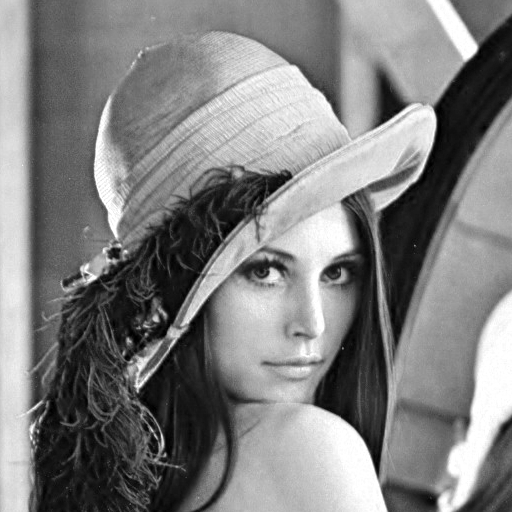

Image Scaling:


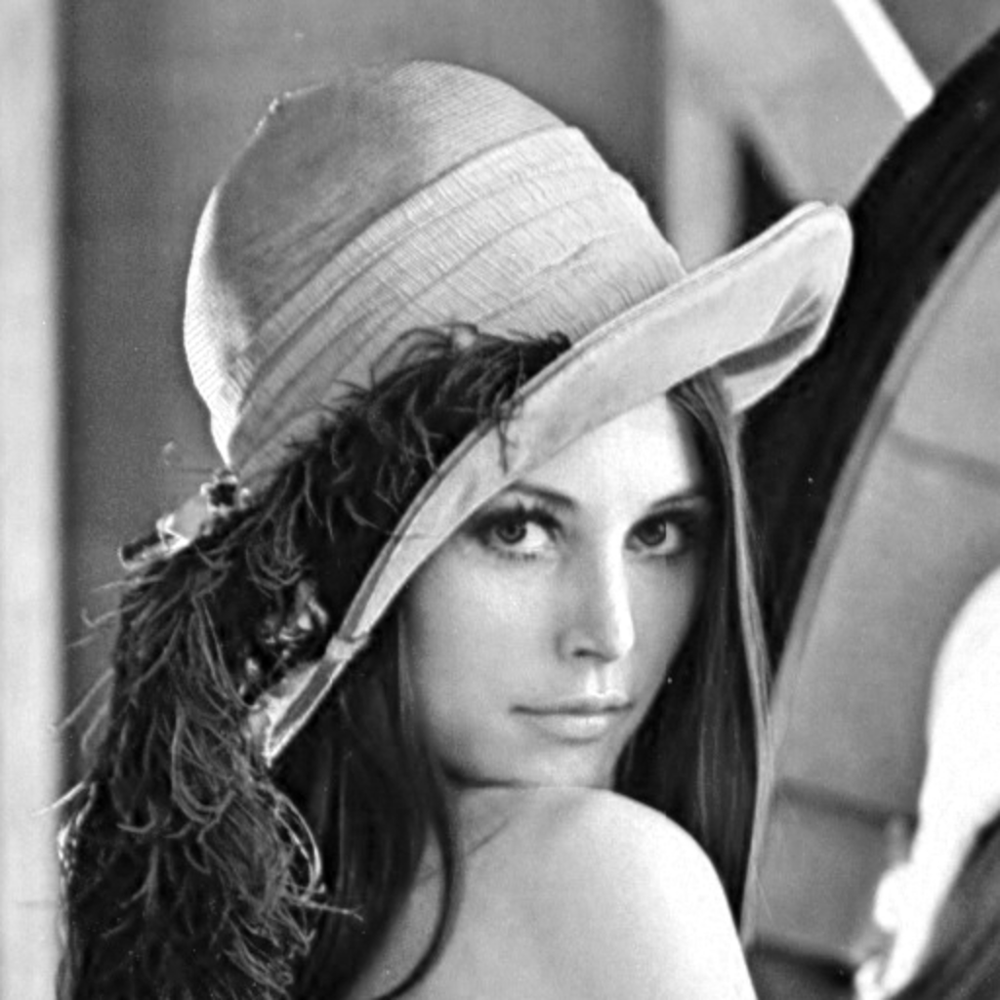

In [ ]:
import cv2
from google.colab.patches import cv2_imshow  # Colab 專用顯示函式

img1 = cv2.imread("Lenna.bmp", -1)
nr, nc = img1.shape[:2]  # nr 是高 (Height), nc 是寬 (Width)

scale = eval(input("Please enter scale: "))
nr2 = int(nr * scale)
nc2 = int(nc * scale)

# 注意：cv2.resize 的尺寸順序是 (寬度 nc2, 高度 nr2)
img2 = cv2.resize(img1, (nc2, nr2), interpolation=cv2.INTER_LINEAR)

# 修正：cv2_imshow() 括號內只能放 1 個參數（影像變數本身）
print("Original Image:")
cv2_imshow(img1)

print("Image Scaling:")
cv2_imshow(img2)



### 縮小影像（Downscaling）— cv2.INTER_AREA

Downscaled_ratio Image:


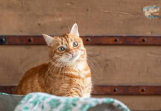

Downscaled_fixed Image:


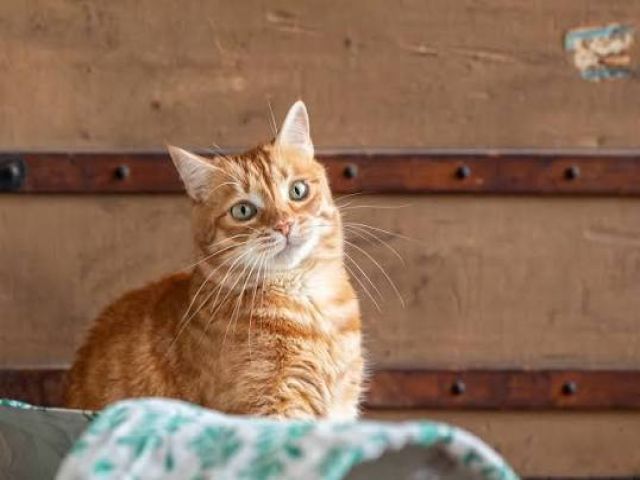

In [ ]:
import cv2
from google.colab.patches import cv2_imshow  # Colab 專用顯示函式

img = cv2.imread("images.jpg")

# 寫法 A：按比例縮小為原本的 30% (0.3 倍)
downscaled_ratio = cv2.resize(
    img, dsize=None, fx=0.3, fy=0.3, interpolation=cv2.INTER_AREA
)
print("Downscaled_ratio Image:")
cv2_imshow(downscaled_ratio)

# 寫法 B：直接指定縮小後的固定寬高 (例如：寬 640, 高 480)
downscaled_fixed = cv2.resize(
    img, dsize=(640, 480), interpolation=cv2.INTER_AREA
)
print("Downscaled_fixed Image:")
cv2_imshow(downscaled_fixed)


### 放大影像（追求速度）— cv2.INTER_LINEAR



Upscaled_fast Image:


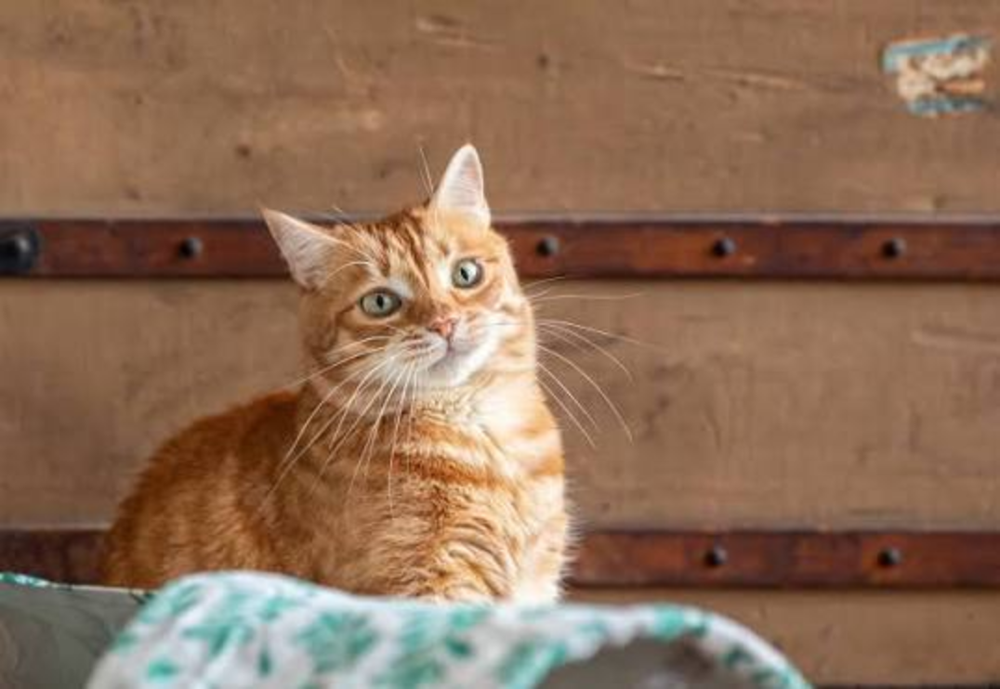

Upscaled_fhd Image:


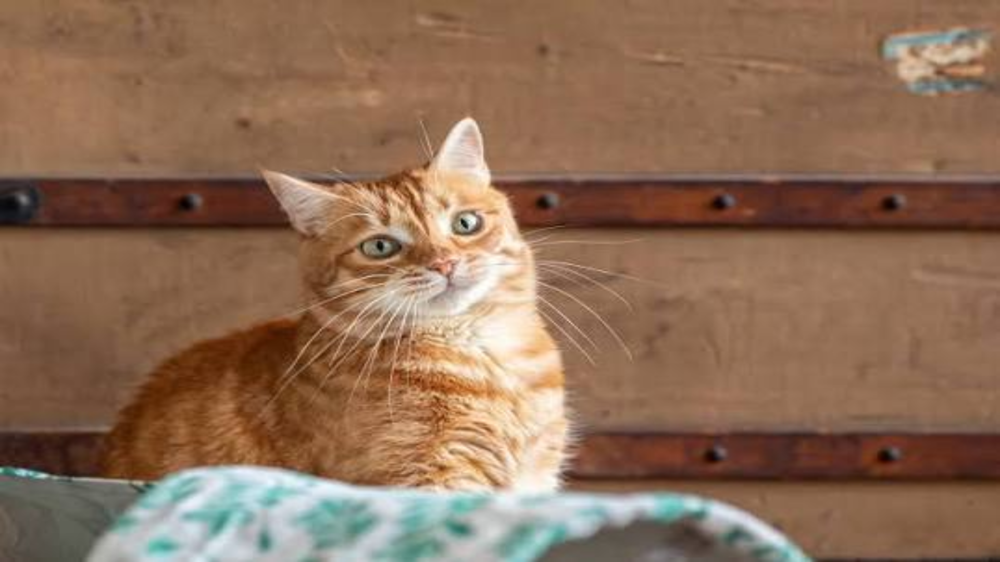

In [ ]:
import cv2
from google.colab.patches import cv2_imshow  # Colab 專用顯示函式

img = cv2.imread("images.jpg")

# 寫法 A：快速將畫面長寬各放大 2 倍 (面積變 4 倍)
upscaled_fast = cv2.resize(
    img, dsize=None, fx=2.0, fy=2.0, interpolation=cv2.INTER_LINEAR
)
print("Upscaled_fast Image:")
cv2_imshow(upscaled_fast)

# 寫法 B：快速放大到 Full HD (寬 1920, 高 1080)
upscaled_fhd = cv2.resize(
    img, dsize=(1920, 1080), interpolation=cv2.INTER_LINEAR
)
print("Upscaled_fhd Image:")
cv2_imshow(upscaled_fhd)



### 放大影像（追求高畫質）— cv2.INTER_CUBIC


Upscaled_hq Image:


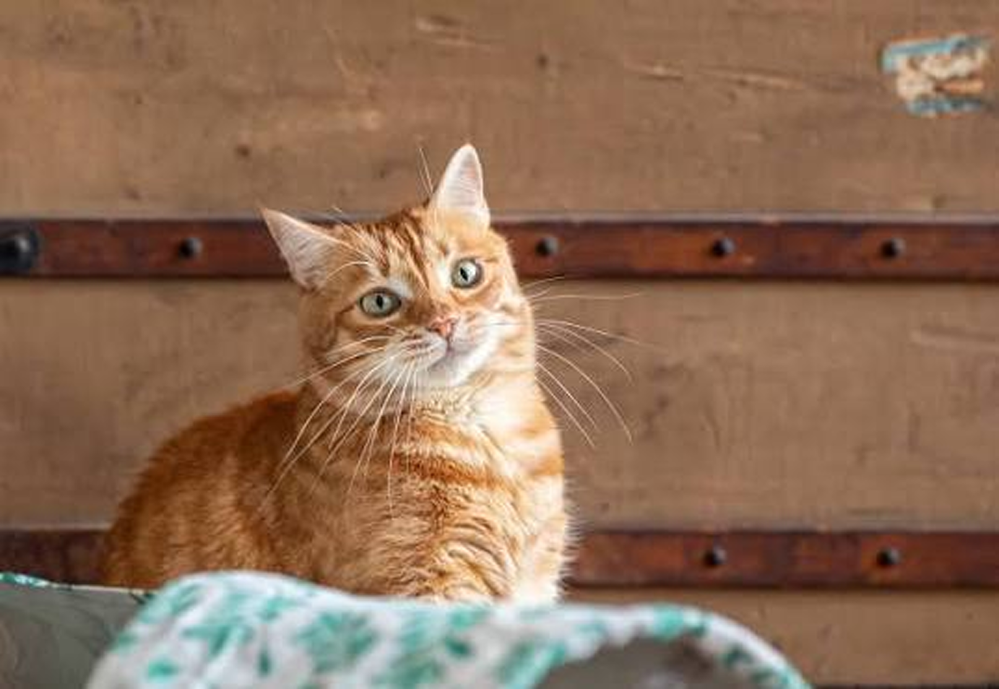

Upscaled_hq_fixed Image:


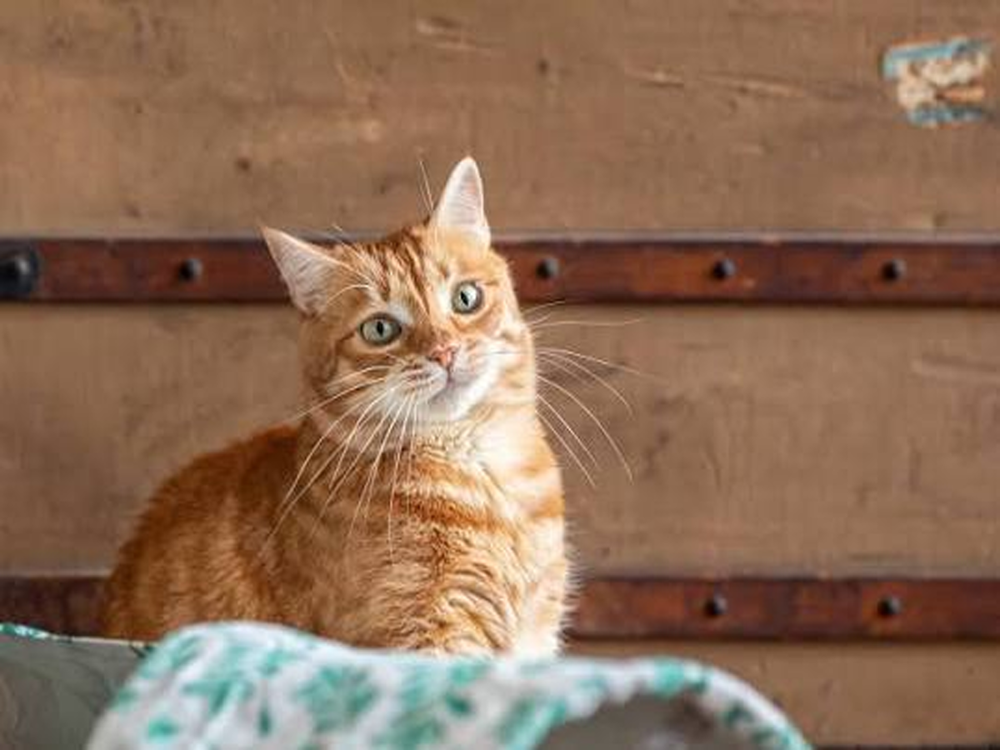

In [ ]:
import cv2
from google.colab.patches import cv2_imshow  # Colab 專用顯示函式

img = cv2.imread("images.jpg")

# 寫法 A：高畫質放大 3 倍
upscaled_hq = cv2.resize(
    img, dsize=None, fx=3.0, fy=3.0, interpolation=cv2.INTER_CUBIC
)
print("Upscaled_hq Image:")
cv2_imshow(upscaled_hq)

# 寫法 B：高畫質放大至指定尺寸 (寬 1200, 高 900)
upscaled_hq_fixed = cv2.resize(
    img, dsize=(1200, 900), interpolation=cv2.INTER_CUBIC
)
print("Upscaled_hq_fixed Image:")
cv2_imshow(upscaled_hq_fixed)

### 縮放學習遮罩（Mask）／像素畫 — cv2.INTER_NEAREST

縮放後的像素類別： [0 1 2]
Pixel_art_large Image:


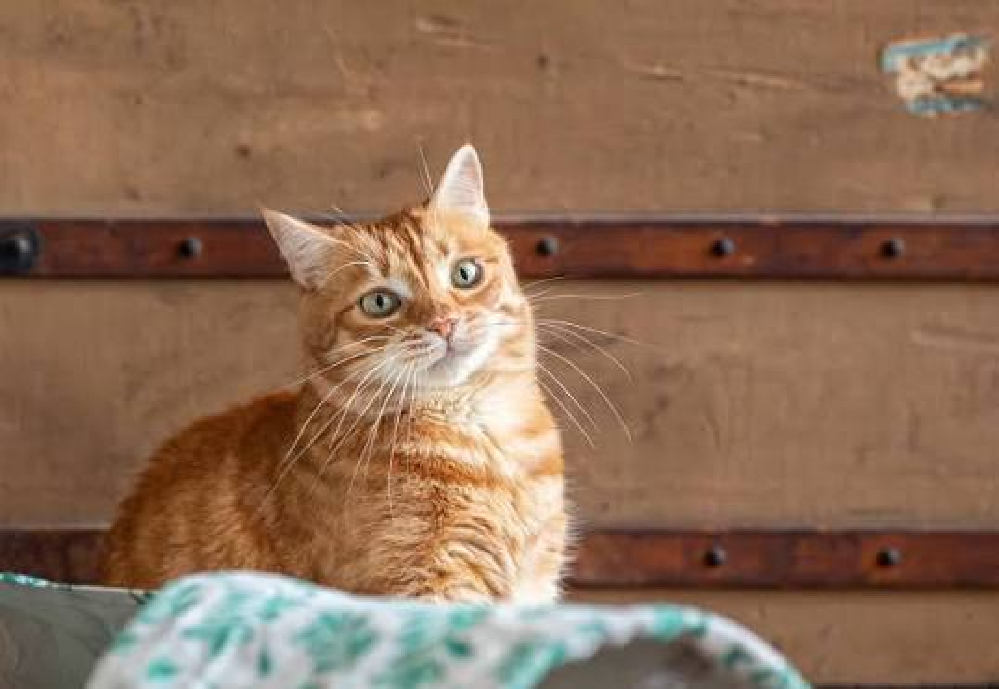

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow  # Colab 專用顯示函式

# 模擬一張 3x3 的深度學習分類遮罩 (只含 0, 1, 2 三種類別標籤)
mask = np.array([
    [0, 0, 1],
    [0, 1, 2],
    [1, 2, 2]
], dtype=np.uint8)

# 1. 將遮罩放大到 (256, 256)，使用 INTER_NEAREST 確保只有 {0, 1, 2} 三種數值
mask_resized = cv2.resize(
    mask, dsize=(256, 256), interpolation=cv2.INTER_NEAREST
)
print("縮放後的像素類別：", np.unique(mask_resized))  # 輸出依然是 [0 1 2]

# 2. 將復古像素畫 (Pixel Art) 放大 10 倍，保留完美馬賽克方格感
pixel_art = cv2.imread("images.jpg")
pixel_art_large = cv2.resize(
    pixel_art, dsize=None, fx=10.0, fy=10.0, interpolation=cv2.INTER_NEAREST
)

print("Pixel_art_large Image:")
cv2_imshow(pixel_art_large)


## 🔁 2.影像旋轉（Rotation）

- 旋轉方法
  1. 固定角度旋轉, 使用 `cv2.rotate`
  2. 任意角度旋轉（標準仿射變換）
  3. 任意角度旋轉（不裁切）
  4. 用 imutils 做影像旋轉

### 固定角度旋轉, 使用 `cv2.rotate`



rot_90_cw image:


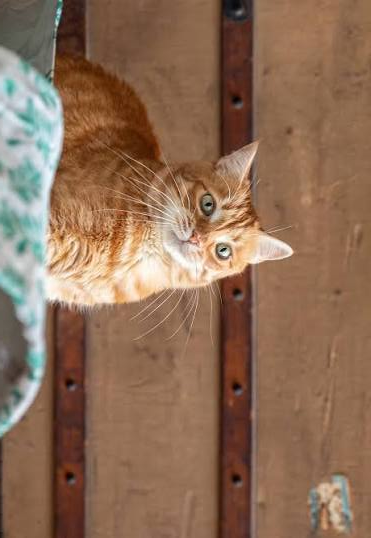

rot_180 image:


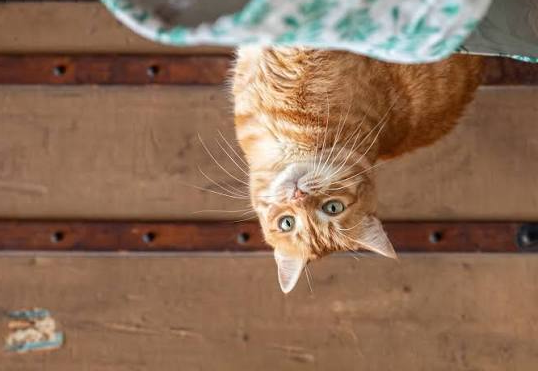

rot_90_ccw image:


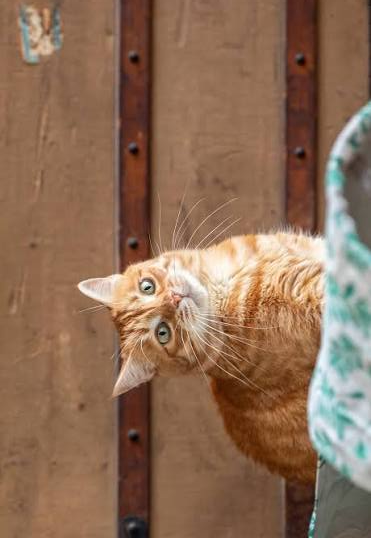

In [ ]:
import cv2
from google.colab.patches import cv2_imshow  # Colab 專用顯示函式

img = cv2.imread("images.jpg")

# 1. 順時針旋轉 90 度
rot_90_cw = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
print("rot_90_cw image:")
cv2_imshow(rot_90_cw)

# 2. 旋轉 180 度
rot_180 = cv2.rotate(img, cv2.ROTATE_180)
print("rot_180 image:")
cv2_imshow(rot_180)

# 3. 逆時針旋轉 90 度（等同順時針 270 度）
rot_90_ccw = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)
print("rot_90_ccw image:")
cv2_imshow(rot_90_ccw)

### 任意角度旋轉（標準仿射變換）



rotated_img


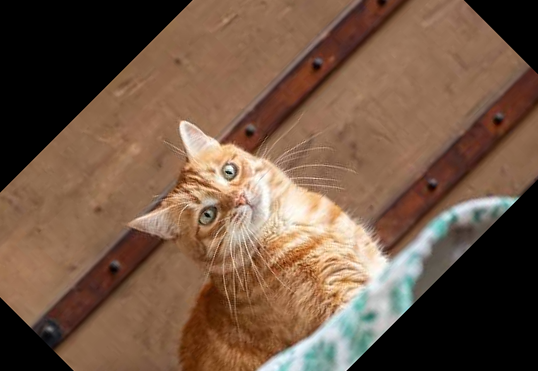

In [ ]:
import cv2
from google.colab.patches import cv2_imshow  # Colab 專用顯示函式

img = cv2.imread("images.jpg")
(h, w) = img.shape[:2]

# 設定旋轉中心為影像正中央
center = (w // 2, h // 2)

# 步驟 1：取得旋轉矩陣（逆時針旋轉 45 度，縮放比例 1.0）
M = cv2.getRotationMatrix2D(center, angle=45, scale=1.0)

# 步驟 2：執行仿射變換（旋轉）
# flags 可以指定插值法（預設為 cv2.INTER_LINEAR，高畫質可用 cv2.INTER_CUBIC）
# borderValue 可設定轉出畫面外的空白處填補顏色，預設為黑色 (0, 0, 0)
rotated_img = cv2.warpAffine(
    img,
    M,
    (w, h),
    flags=cv2.INTER_CUBIC,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(0, 0, 0)
)
print("rotated_img")
cv2_imshow(rotated_img)


### 任意角度旋轉（不裁切）

result


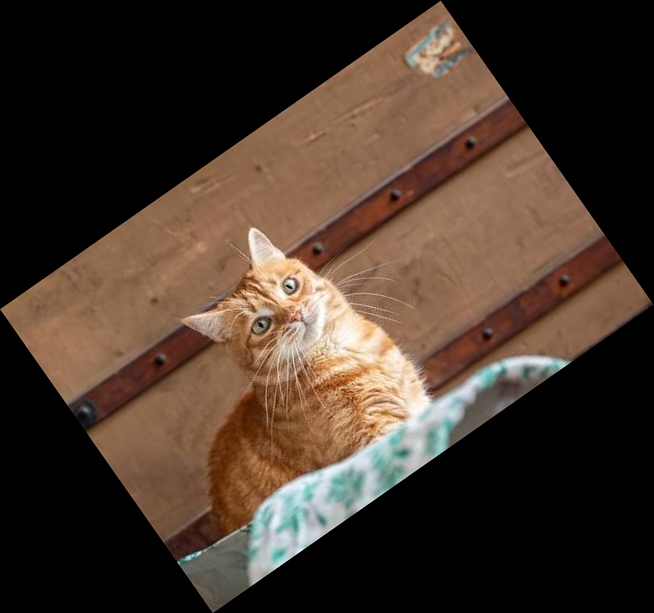

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

def rotate_without_cropping(img, angle):
    (h, w) = img.shape[:2]
    (cX, cY) = (w / 2.0, h / 2.0)

    # 1. 取得基本旋轉矩陣（正數為逆時針）
    M = cv2.getRotationMatrix2D((cX, cY), angle, 1.0)

    # 2. 取出矩陣中的 cos 與 sin 值，計算旋轉後的新邊界寬高
    cos = np.abs(M[0, 0])
    sin = np.abs(M[0, 1])
    new_w = int(np.ceil(h * sin + w * cos))
    new_h = int(np.ceil(h * cos + w * sin))

    # 3. 調整旋轉矩陣的平移量，確保影像位於新畫布的正中央
    M[0, 2] += (new_w / 2.0) - cX
    M[1, 2] += (new_h / 2.0) - cY

    # 4. 進行旋轉（使用新寬高 new_w, new_h）
    return cv2.warpAffine(img, M, (new_w, new_h), flags=cv2.INTER_CUBIC)

img = cv2.imread("images.jpg")
result = rotate_without_cropping(img, 35)
print("result")
cv2_imshow(result)


### 用 imutils 做影像旋轉

rot_cropped


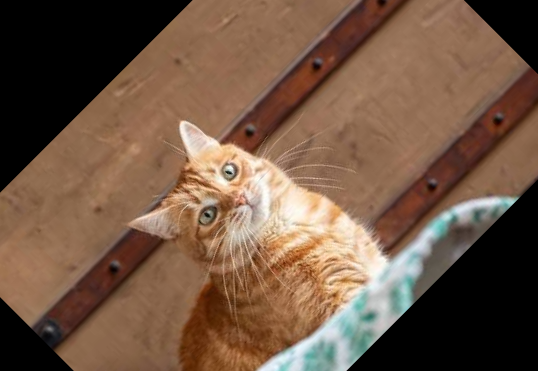

rot_bound


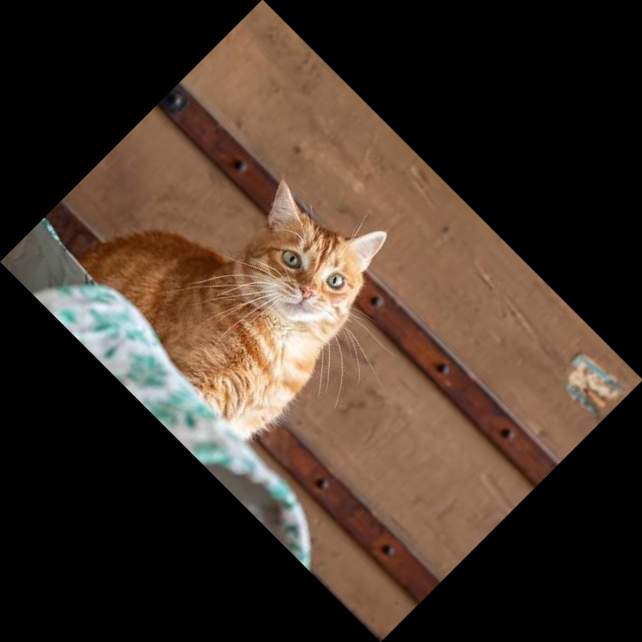

In [ ]:
import cv2
import imutils

img = cv2.imread("images.jpg")

# 一般旋轉（會裁切到邊角，正數為逆時針）
rot_cropped = imutils.rotate(img, angle=45)
print("rot_cropped")
cv2_imshow(rot_cropped)

# 完整保留邊角的旋轉（自動擴大畫布，注意：這裡正數為「順時針」！）
rot_bound = imutils.rotate_bound(img, angle=45)
print("rot_bound")
cv2_imshow(rot_bound)


## 📐 3.影像翻轉（Flipping）

flip_horizontal


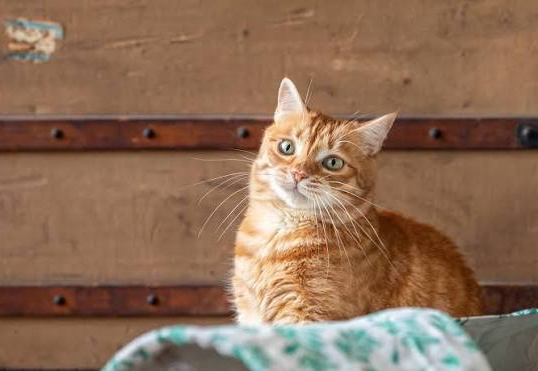

flip_vertical


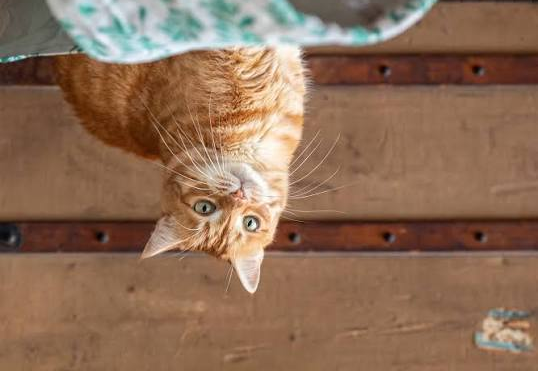

flip_both


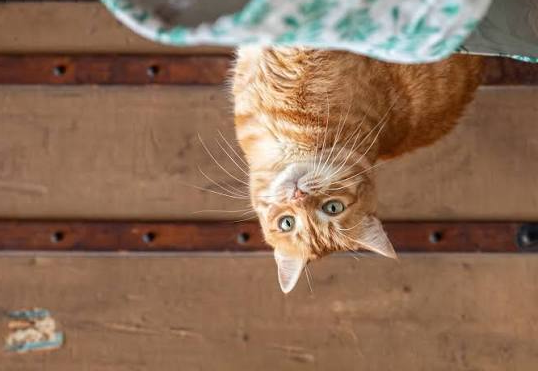

In [ ]:
import cv2
from google.colab.patches import cv2_imshow  # Colab 專用顯示函式

img = cv2.imread("images.jpg")

# 1. 水平翻轉（左右鏡像對調） -> flipCode > 0
flip_horizontal = cv2.flip(img, 1)
print("flip_horizontal")
cv2_imshow(flip_horizontal)

# 2. 垂直翻轉（上下顛倒） -> flipCode == 0
flip_vertical = cv2.flip(img, 0)
print("flip_vertical")
cv2_imshow(flip_vertical)

# 3. 水平 + 垂直同時翻轉（等同旋轉 180 度） -> flipCode < 0
flip_both = cv2.flip(img, -1)
print("flip_both")
cv2_imshow(flip_both)


flip_h


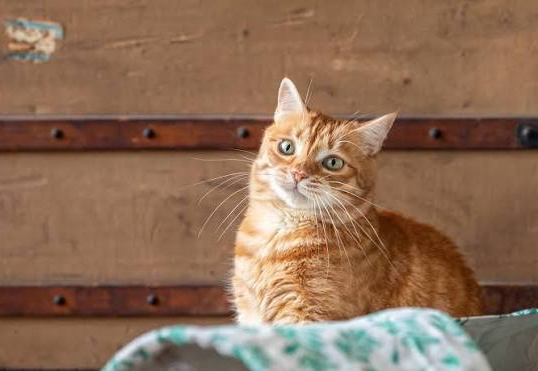

flip_v


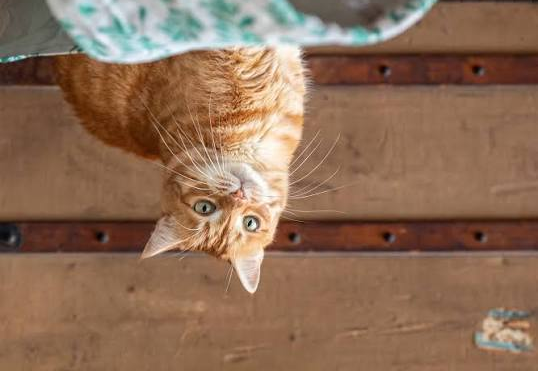

flip_hv


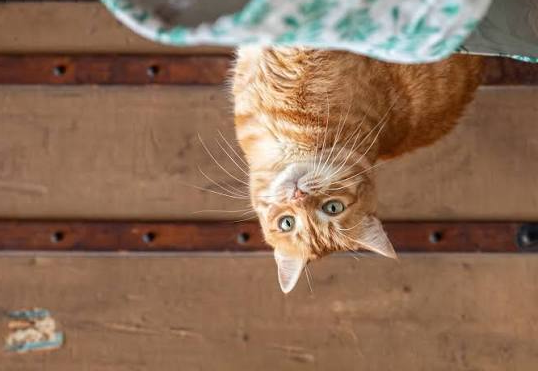

In [ ]:
import cv2
img = cv2.imread("images.jpg")

# 1. 水平翻轉（將第 2 個維度 Width 反向排列）
flip_h = img[:, ::-1]
print("flip_h")
cv2_imshow(flip_h)

# 2. 垂直翻轉（將第 1 個維度 Height 反向排列）
flip_v = img[::-1, :]
print("flip_v")
cv2_imshow(flip_v)

# 3. 水平 + 垂直同時翻轉
flip_hv = img[::-1, ::-1]
print("flip_hv")
cv2_imshow(flip_hv)


## 🔺 4.仿射變換（Affine Transformation）

仿射變換保持平行線的平行關係，需要3個點來定義變換矩陣。

/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 24433 (\N{CJK UNIFIED IDEOGRAPH-5F71}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 32160 (\N{CJK UNIFIED IDEOGRAPH-7DA0}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph

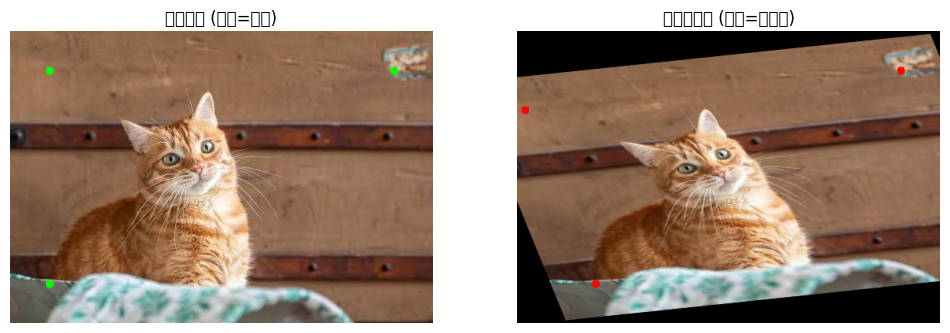

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("images.jpg")

# 仿射變換範例
if image is not None:
    height, width = image.shape[:2]

    # 定義3個源點和目標點
    src_points = np.float32([
        [50, 50],
        [width - 50, 50],
        [50, height - 50]
    ])

    dst_points = np.float32([
        [10, 100],
        [width - 50, 50],
        [100, height - 50]
    ])

    # 獲取仿射變換矩陣
    affine_matrix = cv2.getAffineTransform(src_points, dst_points)

    # 執行仿射變換
    affine_result = cv2.warpAffine(image, affine_matrix, (width, height))

    # 在原圖上標記源點
    image_with_points = image.copy()
    for point in src_points:
        cv2.circle(image_with_points, tuple(point.astype(int)), 5, (0, 255, 0), -1)

    # 在變換後的圖上標記目標點
    result_with_points = affine_result.copy()
    for point in dst_points:
        cv2.circle(result_with_points, tuple(point.astype(int)), 5, (0, 0, 255), -1)

    # 顯示結果
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(cv2.cvtColor(image_with_points, cv2.COLOR_BGR2RGB))
    axes[0].set_title('原始影像 (綠點=源點)')
    axes[0].axis('off')

    axes[1].imshow(cv2.cvtColor(result_with_points, cv2.COLOR_BGR2RGB))
    axes[1].set_title('仿射變換後 (紅點=目標點)')
    axes[1].axis('off')


## 🎭 5.透視變換（Perspective Transformation）

透視變換可以模擬3D視角變化，需要4個點來定義變換矩陣。




### 四點映射與近大遠小（cv2.getPerspectiveTransform）

你的圖片真實尺寸為：寬 538 x 高 371
▼ 原圖（紅框處就是要被拉正的區域）：


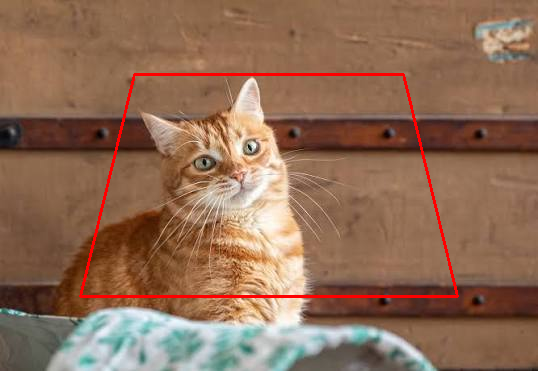

▼ 透視轉換後的正常圖（把紅框拉成正長方形）：


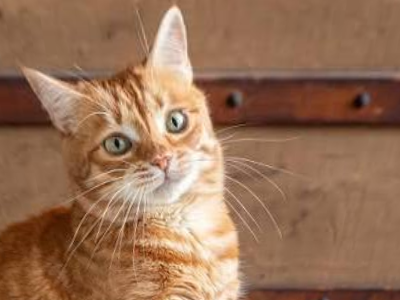

In [ ]:
from google.colab.patches import cv2_imshow
import numpy as np
import cv2

# 1. 讀取影像
img1 = cv2.imread("images.jpg", -1)

if img1 is None:
    print("❌ 找不到 images.jpg！請確認左邊檔案欄有沒有上傳該圖片。")
else:
    # 取得這張圖真正的 高度(nr) 與 寬度(nc)
    nr, nc = img1.shape[:2]
    print(f"你的圖片真實尺寸為：寬 {nc} x 高 {nr}")

    # 2. 根據你的圖片大小，自動設定四個點（順序：左上、左下、右下、右上）
    pts1 = np.float32([
        [nc * 0.25, nr * 0.2],  # 左上角
        [nc * 0.15, nr * 0.8],  # 左下角
        [nc * 0.85, nr * 0.8],  # 右下角
        [nc * 0.75, nr * 0.2]   # 右上角
    ])

    # 設定轉換後的正常長方形大小 (寬 400, 高 300)
    out_w, out_h = 400, 300
    pts2 = np.float32([
        [0, 0],         # 左上
        [0, out_h],       # 左下
        [out_w, out_h],     # 右下
        [out_w, 0]       # 右上
    ])

    # 3. 進行透視轉換
    T = cv2.getPerspectiveTransform(pts1, pts2)
    img2 = cv2.warpPerspective(img1, T, (out_w, out_h))

    # 為了讓你看清楚，我們在原圖上把 pts1 的四個點用紅線框起來
    img_with_box = img1.copy()
    cv2.polylines(img_with_box, [np.int32(pts1)], isClosed=True, color=(0, 0, 255), thickness=2)

    # 4. 顯示結果
    print("▼ 原圖（紅框處就是要被拉正的區域）：")
    cv2_imshow(img_with_box)

    print("▼ 透視轉換後的正常圖（把紅框拉成正長方形）：")
    cv2_imshow(img2)



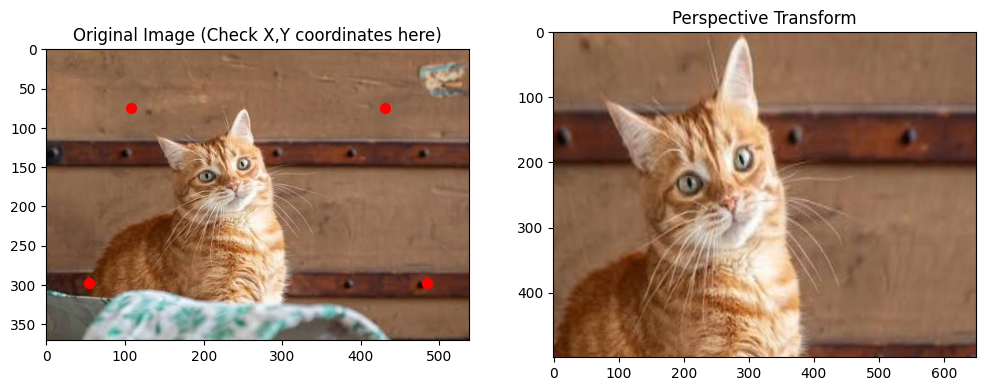

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread("images.jpg")
# 注意：OpenCV 預設是 BGR 顏色，用 matplotlib 顯示要轉成 RGB 顏色才會正常！
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

nr, nc = img1.shape[:2]

# 這裡暫時用圖片中心區域示範，你可以看下圖的刻度尺，改成你想要的四個座標！
pts1 = np.float32([[nc*0.2, nr*0.2], [nc*0.1, nr*0.8], [nc*0.9, nr*0.8], [nc*0.8, nr*0.2]])
pts2 = np.float32([[0, 0], [0, 500], [650, 500], [650, 0]])

T = cv2.getPerspectiveTransform(pts1, pts2)
img2_rgb = cv2.warpPerspective(img1_rgb, T, (650, 500))

# 使用 matplotlib 並排顯示，有標題、有座標尺，顏色也完全正常
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.title("Original Image (Check X,Y coordinates here)")
plt.imshow(img1_rgb)
# 把四個紅點畫在圖上方便核對位置
plt.scatter(pts1[:, 0], pts1[:, 1], color='red', s=50)

plt.subplot(1, 2, 2)
plt.title("Perspective Transform")
plt.imshow(img2_rgb)

plt.show()


### 單應性矩陣估計（cv2.findHomography）

## 🌀6.影像平移與錯切（Translation & Shearing）

### 影像平移 （Translation）

### 影像錯切 / 剪切（Shearing）

## 🔺7.極坐標轉換（Polar Transforms）

### 直角坐標轉極坐標（cv2.linearPolar / cv2.warpPolar）

### 對數極坐標轉換（cv2.logPolar）

##　🛠️8.影像金字塔（Image Pyramids）

### 高斯金字塔（Gaussian Pyramid, cv2.pyrDown, cv2.pyrUp）

### 拉普拉斯金字塔（Laplacian Pyramid）

## 🚀  9. 通用重映射與畸變校正 (Remapping & Lens Correction)

### 自定義映射核心 — cv2.remap

### 相機廣角/魚眼畸變校正 — cv2.undistort